# Transformers from Scratch — NumPy Implementation

All parts use **NumPy only** (Matplotlib for plots). Each question: implementation → shape check → printed to 4 decimal places for comparison with handwritten notes.

Notation: `n` = sequence length, `d_model` = model size, `d_k` / `d_v` = key / value size, `H` = number of heads.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, floatmode="fixed")
np.random.seed(42)

## Q1. Sinusoidal Positional Encoding

$$PE(pos,2i)=\sin\!\left(\frac{pos}{10000^{2i/d}}\right),\qquad PE(pos,2i+1)=\cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

Frequency of pair $i$: $\omega_i = 1/10000^{2i/d}$. Small $i$ → high frequency (changes fast), large $i$ → low frequency (changes slowly).

In [2]:
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return positional encoding matrix of shape (seq_len, d_model)."""
    PE = np.zeros((seq_len, d_model))
    for pos in range(seq_len):
        for i in range(d_model // 2):
            angle = pos / (10000 ** (2 * i / d_model))
            PE[pos, 2 * i] = np.sin(angle)       # even dimension
            PE[pos, 2 * i + 1] = np.cos(angle)   # odd dimension
    return PE


# (b) Values for handwritten comparison: d = 4, pos = 0, 1, 2
PE_small = sinusoidal_positional_encoding(3, 4)
print(PE_small)

[[ 0.0000  1.0000  0.0000  1.0000]
 [ 0.8415  0.5403  0.0100  1.0000]
 [ 0.9093 -0.4161  0.0200  0.9998]]


PE shape: (20, 16)


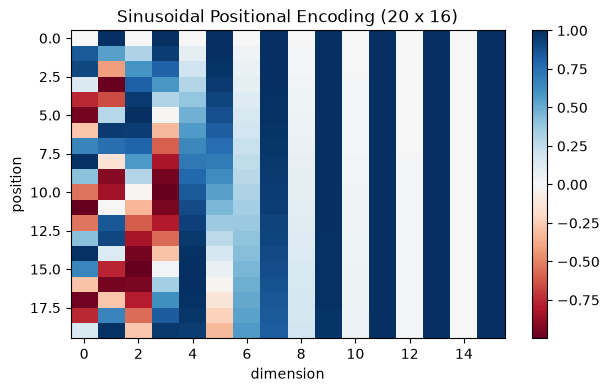

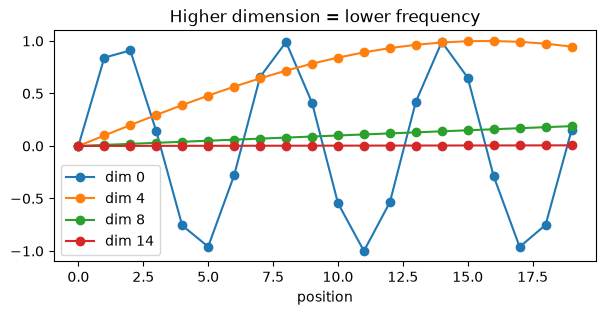

In [3]:
# (c) seq_len = 20, d_model = 16
PE = sinusoidal_positional_encoding(20, 16)
print("PE shape:", PE.shape)

plt.figure(figsize=(7, 4))
plt.imshow(PE, cmap="RdBu", aspect="auto")
plt.colorbar()
plt.xlabel("dimension")
plt.ylabel("position")
plt.title("Sinusoidal Positional Encoding (20 x 16)")
plt.show()

plt.figure(figsize=(7, 3))
for dim in [0, 4, 8, 14]:
    plt.plot(PE[:, dim], marker="o", label=f"dim {dim}")
plt.xlabel("position")
plt.title("Higher dimension = lower frequency")
plt.legend()
plt.show()

**Interpretation.** Each sin/cos pair repeats with period $2\pi/\omega_i$. Fast pairs separate nearby positions, slow pairs separate far
positions. Since $\sin(\omega(p+k))$ and $\cos(\omega(p+k))$ are a rotation of $\sin(\omega p),\cos(\omega p)$ by angle $\omega k$,
the encoding of position $p+k$ is a fixed linear function of position $p$ — so relative positions are easy to learn.

## Q2. Scaled Dot-Product Attention

$\text{Attention}(Q,K,V)=\text{softmax}(QK^\top/\sqrt{d_k})\,V$

Shapes: $Q:(n, d_k)$, $K:(m, d_k)$, $V:(m, d_v)$ → scores $(n, m)$ → output $(n, d_v)$.

In [4]:
def softmax(x):
    """Row-wise softmax (subtract max for stability)."""
    x = x - np.max(x, axis=-1, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=-1, keepdims=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    """Return (output, weights). Q:(n,d_k) K:(m,d_k) V:(m,d_v). mask: (n,m), added to scores."""
    d_k = Q.shape[1]
    scores = Q @ K.T / np.sqrt(d_k)      # (n, m)
    if mask is not None:
        scores = scores + mask
    weights = softmax(scores)            # (n, m), each row sums to 1
    output = weights @ V                 # (n, d_v)
    return output, weights

In [5]:
Q = K = V = np.array([[1.0, 0.0],
                      [0.0, 1.0]])

# (b) Step by step
QKt = Q @ K.T
print("Step 1: QK^T =\n", QKt)

scaled = QKt / np.sqrt(2)                       # d_k = 2
print("Step 2: scaled = QK^T / sqrt(2) =\n", scaled)

exp_scores = np.exp(scaled)
row_sum = exp_scores.sum(axis=1, keepdims=True)
print("Step 3a: exp(scaled) =\n", exp_scores)
print("Step 3b: row sums =\n", row_sum)
softmax_weights = exp_scores / row_sum
print("Step 3c: softmax weights =\n", softmax_weights)

step_output = softmax_weights @ V
print("Step 4: output = weights @ V =\n", step_output)

# (d) Verification: function result vs step-by-step result
output, weights = scaled_dot_product_attention(Q, K, V)
print("\nfunction weights =\n", weights)
print("function output =\n", output)
print("row sums of weights:", weights.sum(axis=1))
print("function == step-by-step:", np.allclose(output, step_output))

Step 1: QK^T =
 [[1.0000 0.0000]
 [0.0000 1.0000]]
Step 2: scaled = QK^T / sqrt(2) =
 [[0.7071 0.0000]
 [0.0000 0.7071]]
Step 3a: exp(scaled) =
 [[2.0281 1.0000]
 [1.0000 2.0281]]
Step 3b: row sums =
 [[3.0281]
 [3.0281]]
Step 3c: softmax weights =
 [[0.6698 0.3302]
 [0.3302 0.6698]]
Step 4: output = weights @ V =
 [[0.6698 0.3302]
 [0.3302 0.6698]]

function weights =
 [[0.6698 0.3302]
 [0.3302 0.6698]]
function output =
 [[0.6698 0.3302]
 [0.3302 0.6698]]
row sums of weights: [1.0000 1.0000]
function == step-by-step: True


## Q3. Q, K, V Projections

$Q=XW_Q,\;K=XW_K,\;V=XW_V$. With $X:(n, d_{model})$: $W_Q, W_K:(d_{model}, d_k)$, $W_V:(d_{model}, d_v)$.
Separate matrices let a token *ask* (query), *advertise* (key) and *send* (value) different information.

In [6]:
def self_attention(X, W_Q, W_K, W_V):
    """Project X into Q, K, V and apply scaled dot-product attention."""
    Q = X @ W_Q      # (n, d_k)
    K = X @ W_K      # (n, d_k)
    V = X @ W_V      # (n, d_v)
    output, weights = scaled_dot_product_attention(Q, K, V)
    return output, weights, Q, K, V


X = np.array([[1.0, 2.0],
              [0.0, 1.0]])
W_Q = np.array([[1.0, 0.0], [0.0, 1.0]])
W_K = np.array([[0.0, 1.0], [1.0, 0.0]])
W_V = np.array([[2.0, 0.0], [0.0, 1.0]])

output, weights, Q, K, V = self_attention(X, W_Q, W_K, W_V)
print("Q =\n", Q, "\nK =\n", K, "\nV =\n", V)
print("scaled scores =\n", Q @ K.T / np.sqrt(2))
print("weights =\n", weights)
print("output =\n", output)

Q =
 [[1.0000 2.0000]
 [0.0000 1.0000]] 
K =
 [[2.0000 1.0000]
 [1.0000 0.0000]] 
V =
 [[2.0000 2.0000]
 [0.0000 1.0000]]
scaled scores =
 [[2.8284 0.7071]
 [0.7071 0.0000]]
weights =
 [[0.8930 0.1070]
 [0.6698 0.3302]]
output =
 [[1.7859 1.8930]
 [1.3395 1.6698]]


In [7]:
# (d) Identity projections vs supplied projections (same X)
I = np.eye(2)
output_id, weights_id, Q_id, K_id, V_id = self_attention(X, I, I, I)

print("---- Scores (QK^T / sqrt(2)) ----")
print("identity:\n", Q_id @ K_id.T / np.sqrt(2))
print("supplied:\n", Q @ K.T / np.sqrt(2))

print("\n---- Attention weights ----")
print("identity:\n", weights_id)
print("supplied:\n", weights)

print("\n---- Output ----")
print("identity:\n", output_id)
print("supplied:\n", output)

---- Scores (QK^T / sqrt(2)) ----
identity:
 [[3.5355 1.4142]
 [1.4142 0.7071]]
supplied:
 [[2.8284 0.7071]
 [0.7071 0.0000]]

---- Attention weights ----
identity:
 [[0.8930 0.1070]
 [0.6698 0.3302]]
supplied:
 [[0.8930 0.1070]
 [0.6698 0.3302]]

---- Output ----
identity:
 [[0.8930 1.8930]
 [0.6698 1.6698]]
supplied:
 [[1.7859 1.8930]
 [1.3395 1.6698]]


**Analysis.**

| | Identity | Supplied |
|---|---|---|
| Scores | [[3.536, 1.414], [1.414, 0.707]] | [[2.828, 0.707], [0.707, 0.000]] |
| Weights | [[0.8930, 0.1070], [0.6698, 0.3302]] | same |
| Output | [[0.8930, 1.8930], [0.6698, 1.6698]] | [[1.7860, 1.8930], [1.3396, 1.6698]] |

- **Scores changed:** $W_K$ swaps the features of each key, so how well each query matches each key changes.
  With identity, scores are just $XX^\top$, so token relationships come only from raw similarity of the inputs.
- **Weights did not change here:** softmax only depends on the gap inside each row, and those gaps are the same
  (2.121 and 0.707). This is a coincidence of these numbers. Other matrices would give different weights.
- **Output changed:** $W_V$ doubles the first feature, so the information passed between tokens changes.

**Conclusion:** $W_Q, W_K$ decide *who attends to whom* (token relationships). $W_V$ decides *what is passed*.
Learned projections let the model build relationships that are different from raw input similarity.

## Q4. Causal Self-Attention

$A=\text{softmax}(QK^\top/\sqrt{d_k}+M)$, $M_{ij}=0$ if $j\le i$, else $-\infty$. A token cannot look at future tokens.

In [8]:
def causal_mask(n):
    """Return (n, n) mask: 0 on/below diagonal, -inf above (future)."""
    mask = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if j > i:
                mask[i, j] = -np.inf
    return mask


def causal_self_attention(Q, K, V):
    """Attention where token i only sees tokens 0..i."""
    return scaled_dot_product_attention(Q, K, V, mask=causal_mask(Q.shape[0]))


print("4 x 4 causal mask:\n", causal_mask(4))

4 x 4 causal mask:
 [[0.0000   -inf   -inf   -inf]
 [0.0000 0.0000   -inf   -inf]
 [0.0000 0.0000 0.0000   -inf]
 [0.0000 0.0000 0.0000 0.0000]]


In [9]:
Q = K = V = np.array([[1.0, 0.0],
                      [0.0, 1.0],
                      [1.0, 1.0]])

scores = Q @ K.T / np.sqrt(2)
print("scaled scores =\n", scores)
print("masked scores =\n", scores + causal_mask(3))

output, weights = causal_self_attention(Q, K, V)
print("weights =\n", weights)
print("output =\n", output)


future = weights[np.triu_indices(3, k=1)]   # entries above diagonal
print("future weights:", future, "-> all zero:", np.all(future == 0))

scaled scores =
 [[0.7071 0.0000 0.7071]
 [0.0000 0.7071 0.7071]
 [0.7071 0.7071 1.4142]]
masked scores =
 [[0.7071   -inf   -inf]
 [0.0000 0.7071   -inf]
 [0.7071 0.7071 1.4142]]
weights =
 [[1.0000 0.0000 0.0000]
 [0.3302 0.6698 0.0000]
 [0.2483 0.2483 0.5035]]
output =
 [[1.0000 0.0000]
 [0.3302 0.6698]
 [0.7517 0.7517]]
future weights: [0.0000 0.0000 0.0000] -> all zero: True


**Causal vs padding mask.** Causal mask blocks *future positions* (fixed triangle shape). Padding mask blocks `<pad>` tokens
(depends on the sentence length) and is used in both encoder and decoder.

## Q5. Cross-Attention

Q comes from the **decoder**, K and V come from the **encoder**. With $n$ decoder and $m$ encoder tokens, scores are $(n, m)$ — not square.

In [10]:
def cross_attention(decoder_states, encoder_states, W_Q, W_K, W_V):
    """Decoder tokens (n) attend to encoder tokens (m). Returns output (n,d_v), weights (n,m)."""
    Q = decoder_states @ W_Q     # (n, d_k)
    K = encoder_states @ W_K     # (m, d_k)
    V = encoder_states @ W_V     # (m, d_v)
    return scaled_dot_product_attention(Q, K, V)


# (b) Q, K, V are given directly -> use attention on them
Q = np.array([[1.0, 0.0]])
K = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
V = np.array([[2.0, 0.0], [0.0, 2.0], [1.0, 1.0]])

output, weights = scaled_dot_product_attention(Q, K, V)
print("scaled scores:", Q @ K.T / np.sqrt(2))
print("weights:", weights)
print("output:", output)

scaled scores: [[0.7071 0.0000 0.7071]]
weights: [[0.4011 0.1978 0.4011]]
output: [[1.2033 0.7967]]


In [11]:
# (c) Function with projections: 2 decoder tokens, 4 encoder tokens, d_model = 4
decoder_states = np.random.randn(2, 4)
encoder_states = np.random.randn(4, 4)
W = np.eye(4)

output, weights = cross_attention(decoder_states, encoder_states, W, W, W)
print("output shape :", output.shape)    # (2, 4)
print("weights shape:", weights.shape)   # (2, 4)  -> n x m

output shape : (2, 4)
weights shape: (2, 4)


## Q6. Multi-Head Attention

$d_{model}=8,\;H=2 \Rightarrow d_k=d_v=4$. $W_Q,W_K,W_V,W_O:(8,8)$. Each head uses 4 columns → head output $(n,4)$ →
concat $(n,8)$ → $\times W_O$ → $(n,8)$.

In [12]:
def multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads, kv=None, mask=None):
    """Return output (n, d_model) and weights (num_heads, n, m).
    kv: source for keys/values (default X = self-attention; encoder output = cross-attention).
    """
    if kv is None:
        kv = X
    Q = X @ W_Q      # (n, d_model)
    K = kv @ W_K     # (m, d_model)
    V = kv @ W_V     # (m, d_model)

    d_head = Q.shape[1] // num_heads
    head_outputs = []
    head_weights = []
    for h in range(num_heads):
        cols = slice(h * d_head, (h + 1) * d_head)     # columns of this head
        out, w = scaled_dot_product_attention(Q[:, cols], K[:, cols], V[:, cols], mask)
        head_outputs.append(out)                       # (n, d_head)
        head_weights.append(w)                         # (n, m)

    concat = np.concatenate(head_outputs, axis=1)      # (n, d_model)
    return concat @ W_O, np.array(head_weights)

In [13]:
# (b) Handwritten example: X = I2, two heads, each head has d_k = 2
X = np.eye(2)
I = np.eye(2)
P = np.array([[0.0, 1.0], [1.0, 0.0]])

# Put the two heads side by side: [head1 | head2]
W_Q = np.hstack([I, P])
W_K = np.hstack([I, P])
W_V = np.hstack([I, I])
W_O = np.eye(4)            # no output projection

output, weights = multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads=2)
print("head 1 weights:\n", weights[0])
print("head 2 weights:\n", weights[1])
print("concat:\n", output)

head 1 weights:
 [[0.6698 0.3302]
 [0.3302 0.6698]]
head 2 weights:
 [[0.6698 0.3302]
 [0.3302 0.6698]]
concat:
 [[0.6698 0.3302 0.6698 0.3302]
 [0.3302 0.6698 0.3302 0.6698]]


output shape : (5, 8)
weights shape: (2, 5, 5)


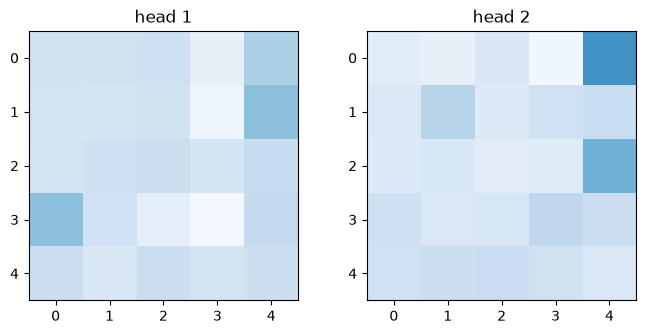

In [14]:
# (c) d_model = 8, H = 2, random input of 5 tokens
d_model = 8
X = np.random.randn(5, d_model)
W_Q, W_K, W_V, W_O = [np.random.randn(d_model, d_model) * 0.3 for _ in range(4)]

output, weights = multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads=2)
print("output shape :", output.shape)    # (5, 8)
print("weights shape:", weights.shape)   # (2, 5, 5)

fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for h in range(2):
    ax[h].imshow(weights[h], cmap="Blues", vmin=0, vmax=1)
    ax[h].set_title(f"head {h + 1}")
plt.show()

**Analysis.** Each head has its own projection, so it can focus on a different relationship (nearby words, subject–verb, etc.).
Total size stays $d_{model}$, so more heads means smaller $d_k$ per head — each head becomes weaker, so more heads does not always help.

## Q7. Numerical Stability and Temperature

$\text{softmax}(z-c)_i=\frac{e^{z_i}e^{-c}}{\sum_j e^{z_j}e^{-c}}=\text{softmax}(z)_i$. Using $c=\max(z)$ keeps all exponents $\le 0$, so no overflow.

In [15]:
def stable_softmax(x, axis=-1):
    """Numerically stable softmax: subtract max before exp."""
    x = np.asarray(x, dtype=float)
    e = np.exp(x - np.max(x, axis=axis, keepdims=True))
    return e / np.sum(e, axis=axis, keepdims=True)


z = np.array([1000.0, 1001.0, 1002.0])

with np.errstate(over="ignore", invalid="ignore"):
    direct = np.exp(z) / np.sum(np.exp(z))
print("direct exp:", direct)          # overflow -> nan
print("stable    :", stable_softmax(z))

direct exp: [nan nan nan]
stable    : [0.0900 0.2447 0.6652]


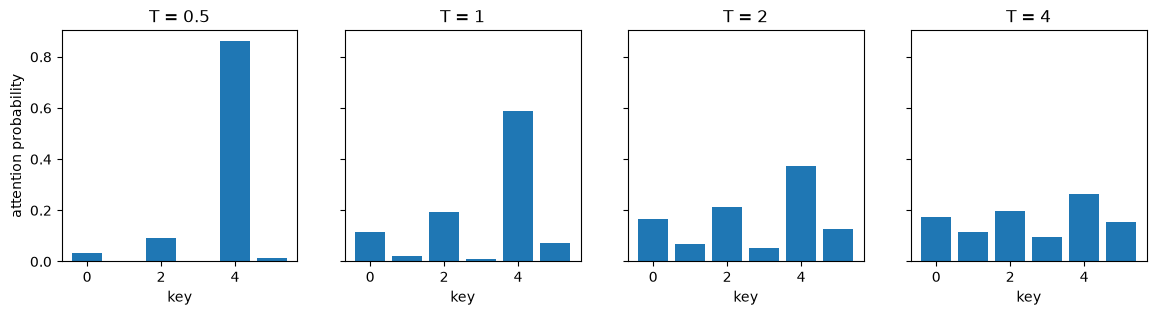

In [16]:
# (c) Temperature: softmax(QK^T / T)
Q = np.random.randn(1, 8)
K = np.random.randn(6, 8)
scores = Q @ K.T                     # (1, 6)

fig, ax = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for a, T in zip(ax, [0.5, 1, 2, 4]):
    probs = stable_softmax(scores / T)[0]
    a.bar(range(6), probs)
    a.set_title(f"T = {T}")
    a.set_xlabel("key")
ax[0].set_ylabel("attention probability")
plt.show()

Small $T$ → sharp (almost one-hot) attention, softmax saturates and gradients become tiny. Large $T$ → flat attention.
Dividing by $\sqrt{d_k}$ is a temperature that keeps scores in a healthy range.

## Q8. Transformer Encoder Block (post-norm)

$H=\text{LayerNorm}(X+\text{MHA}(X))$, $\;Y=\text{LayerNorm}(H+\text{FFN}(H))$, $\;\text{FFN}(H)=\text{ReLU}(HW_1+b_1)W_2+b_2$

Shapes: $X, H, Y:(n, d_{model})$, $W_1:(d_{model}, d_{ff})$, $W_2:(d_{ff}, d_{model})$.

In [17]:
def layer_norm(X, gamma, beta, eps=1e-5):
    """Normalize each token (row) to mean 0, variance 1, then scale and shift."""
    mean = X.mean(axis=1, keepdims=True)    # (n, 1)
    var = X.var(axis=1, keepdims=True)      # (n, 1)
    return gamma * (X - mean) / np.sqrt(var + eps) + beta


def feed_forward(X, W1, b1, W2, b2):
    """Same 2-layer ReLU network applied to every token: (n,d_model) -> (n,d_ff) -> (n,d_model)."""
    hidden = np.maximum(0, X @ W1 + b1)
    return hidden @ W2 + b2


def transformer_encoder_block(X, params):
    """Return (seq_len, d_model) output."""
    p = params
    attn, _ = multi_head_attention(X, p["W_Q"], p["W_K"], p["W_V"], p["W_O"], p["num_heads"])
    H = layer_norm(X + attn, p["gamma1"], p["beta1"])          # add & norm

    ffn = feed_forward(H, p["W1"], p["b1"], p["W2"], p["b2"])
    Y = layer_norm(H + ffn, p["gamma2"], p["beta2"])           # add & norm
    return Y

In [18]:
d_model, d_ff, num_heads = 8, 32, 2

encoder_params = {
    "num_heads": num_heads,
    "W_Q": np.random.randn(d_model, d_model) * 0.3,
    "W_K": np.random.randn(d_model, d_model) * 0.3,
    "W_V": np.random.randn(d_model, d_model) * 0.3,
    "W_O": np.random.randn(d_model, d_model) * 0.3,
    "W1": np.random.randn(d_model, d_ff) * 0.3, "b1": np.zeros(d_ff),
    "W2": np.random.randn(d_ff, d_model) * 0.3, "b2": np.zeros(d_model),
    "gamma1": np.ones(d_model), "beta1": np.zeros(d_model),
    "gamma2": np.ones(d_model), "beta2": np.zeros(d_model),
}

src_len = 5
X_src = np.random.randn(src_len, d_model) + sinusoidal_positional_encoding(src_len, d_model)
Y = transformer_encoder_block(X_src, encoder_params)

print("input shape :", X_src.shape)
print("output shape:", Y.shape)
print("mean of each token:", Y.mean(axis=1))   # ~0 after layer norm
print("std of each token :", Y.std(axis=1))    # ~1 after layer norm

input shape : (5, 8)
output shape: (5, 8)
mean of each token: [-0.0000  0.0000  0.0000 -0.0000  0.0000]
std of each token : [1.0000 1.0000 1.0000 1.0000 1.0000]


## Q9. Transformer Decoder Block

Steps: (1) masked self-attention → (2) add & norm → (3) cross-attention (Q from decoder, K/V from encoder) → (4) add & norm
→ (5) FFN → (6) add & norm.

In [19]:
def transformer_decoder_block(decoder_input, encoder_output, params):
    """Return decoder output (n, d_model) plus self- and cross-attention weights."""
    p = params
    n = decoder_input.shape[0]

    # (1) masked self-attention + (2) add & norm
    self_attn, self_w = multi_head_attention(
        decoder_input, p["sa_W_Q"], p["sa_W_K"], p["sa_W_V"], p["sa_W_O"],
        p["num_heads"], mask=causal_mask(n))
    H1 = layer_norm(decoder_input + self_attn, p["gamma1"], p["beta1"])

    # (3) cross-attention + (4) add & norm
    cross_attn, cross_w = multi_head_attention(
        H1, p["ca_W_Q"], p["ca_W_K"], p["ca_W_V"], p["ca_W_O"],
        p["num_heads"], kv=encoder_output)
    H2 = layer_norm(H1 + cross_attn, p["gamma2"], p["beta2"])

    # (5) feed-forward + (6) add & norm
    ffn = feed_forward(H2, p["W1"], p["b1"], p["W2"], p["b2"])
    Y = layer_norm(H2 + ffn, p["gamma3"], p["beta3"])

    print("decoder input     :", decoder_input.shape)
    print("encoder output    :", encoder_output.shape)
    print("self-attn weights :", self_w.shape)
    print("after step 2 (H1) :", H1.shape)
    print("cross-attn weights:", cross_w.shape)
    print("after step 4 (H2) :", H2.shape)
    print("decoder output    :", Y.shape)
    return Y, self_w, cross_w

In [20]:
decoder_params = {"num_heads": num_heads}
for name in ["sa_W_Q", "sa_W_K", "sa_W_V", "sa_W_O", "ca_W_Q", "ca_W_K", "ca_W_V", "ca_W_O"]:
    decoder_params[name] = np.random.randn(d_model, d_model) * 0.3
decoder_params.update({
    "W1": np.random.randn(d_model, d_ff) * 0.3, "b1": np.zeros(d_ff),
    "W2": np.random.randn(d_ff, d_model) * 0.3, "b2": np.zeros(d_model),
    "gamma1": np.ones(d_model), "beta1": np.zeros(d_model),
    "gamma2": np.ones(d_model), "beta2": np.zeros(d_model),
    "gamma3": np.ones(d_model), "beta3": np.zeros(d_model),
})

tgt_len = 3
encoder_output = transformer_encoder_block(X_src, encoder_params)                  # (5, 8)
X_tgt = np.random.randn(tgt_len, d_model) + sinusoidal_positional_encoding(tgt_len, d_model)

Y, self_w, cross_w = transformer_decoder_block(X_tgt, encoder_output, decoder_params)

print("\nmasked self-attention weights (head 1):\n", self_w[0])   # upper triangle = 0
print("cross-attention weights (head 1):\n", cross_w[0])          # 3 x 5

decoder input     : (3, 8)
encoder output    : (5, 8)
self-attn weights : (2, 3, 3)
after step 2 (H1) : (3, 8)
cross-attn weights: (2, 3, 5)
after step 4 (H2) : (3, 8)
decoder output    : (3, 8)

masked self-attention weights (head 1):
 [[1.0000 0.0000 0.0000]
 [0.6516 0.3484 0.0000]
 [0.1007 0.5217 0.3776]]
cross-attention weights (head 1):
 [[0.1883 0.2132 0.1696 0.2541 0.1748]
 [0.1171 0.3207 0.0845 0.3514 0.1263]
 [0.1568 0.2978 0.1230 0.2409 0.1816]]


## Q10. Complexity and Benchmark

- Q/K/V projections: $3 \cdot n \cdot d_{model}^2$ (per head $n \cdot d_{model} \cdot d_k$)
- $QK^\top$: per head $n^2 d_k$, total $n^2 d_{model}$
- $AV$: per head $n^2 d_v$, total $n^2 d_{model}$
- Attention matrix memory: $H \cdot n^2$ numbers

n =   32 | time =   0.134 ms | attention memory =  0.031 MB
n =   64 | time =   0.249 ms | attention memory =  0.125 MB
n =  128 | time =   0.842 ms | attention memory =  0.500 MB


n =  256 | time =   4.346 ms | attention memory =  2.000 MB


n =  512 | time =  30.990 ms | attention memory =  8.000 MB


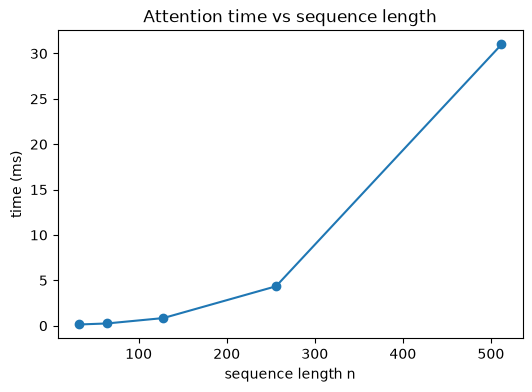

In [21]:
def benchmark_attention(seq_lengths, d_model, num_heads):
    """Time multi-head attention and compute attention-matrix memory for each length."""
    W_Q, W_K, W_V, W_O = [np.random.randn(d_model, d_model) for _ in range(4)]
    times_ms = []
    memory_mb_list = []
    for n in seq_lengths:
        X = np.random.randn(n, d_model)

        start = time.perf_counter()
        for _ in range(10):
            multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads)
        elapsed_ms = (time.perf_counter() - start) / 10 * 1000

        memory_mb = num_heads * n * n * 8 / 1024**2     # float64 = 8 bytes
        times_ms.append(elapsed_ms)
        memory_mb_list.append(memory_mb)
        print(f"n = {n:4d} | time = {elapsed_ms:7.3f} ms | attention memory = {memory_mb:6.3f} MB")
    return times_ms, memory_mb_list


seq_lengths = [32, 64, 128, 256, 512]
times_ms, memory_mb = benchmark_attention(seq_lengths, d_model=64, num_heads=4)

plt.figure(figsize=(6, 4))
plt.plot(seq_lengths, times_ms, marker="o")
plt.xlabel("sequence length n")
plt.ylabel("time (ms)")
plt.title("Attention time vs sequence length")
plt.show()

**Observation.** Doubling $n$ makes attention memory 4× larger ($n^2$). Time grows roughly quadratically once $n$ is larger than
$d_{model}$. A causal mask hides half the scores but this code still computes the full $n \times n$ matrix, so it saves no time here.